# 04 - What drives churn risk (SHAP)

**What is explained.** The champion in the MLflow registry (`bank-churn-model@champion`, **version 2: the model without Gender**, 16 features; see the ablation near the end) is a calibrated ensemble: five XGBoost models, one per cross-validation fold,
each followed by its own isotonic calibrator. SHAP (`TreeExplainer`) is computed on each of the five XGBoost models for the test customers and averaged.

**Why it is fine to explain the trees and not the calibrated probability.** Isotonic calibration is a monotonic transformation: it changes the probability values but not the ordering of customers.
Each fold model's calibrator preserves that model's ranking, and the champion averages five of them, so its ranking matches the averaged tree scores almost exactly
(Spearman correlation printed below). The drivers of the tree score are therefore the drivers of who ranks as high risk. Probabilities themselves (used in Stage 5) come from the calibrated model.

**Units.** SHAP values are in log-odds of churn: positive pushes a customer toward churning, negative away from it. For every customer, the base value plus all SHAP values equals the model's log-odds (checked below).

**Levers.** Each feature is tagged *Customer*, *Product* or *Engagement*, following the Stage 2 split. Balance-based features (`Balance`, `zero_balance`, `balance_to_salary`) sit under *Product*,
as in the EDA. `active_x_products` sits under *Engagement* because it is an activity flag times product count. `Tenure` is *Engagement*.

**Read with care.** SHAP describes what the model relies on, not what causes churn. Correlated features share credit (for example `Age` and `is_senior`, or `NumOfProducts` and `active_x_products`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from matplotlib.patches import Patch
from scipy.stats import spearmanr

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from src.models.drivers import LEVER_OF, champion_shap
from src.models.registry import load_champion, load_test_features

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
LEVER_COLORS = {"Customer": "#2a78d6", "Product": "#eb6834", "Engagement": "#1baf7a"}

X, y = load_test_features()
champion = load_champion()
sv, base, margin = champion_shap(champion, X)
risk = champion.predict_proba(X)[:, 1]

print(f"{len(X):,} test customers, {X.shape[1]} features")
print(f"additivity: max |SHAP sum + base - model log-odds| = {np.abs(sv.sum(axis=1) + base - margin).max():.2e}")
print(f"ranking agreement: Spearman(averaged tree log-odds, calibrated champion probability) = {spearmanr(margin, risk).statistic:.4f}")

2,000 test customers, 16 features
additivity: max |SHAP sum + base - model log-odds| = 1.91e-06
ranking agreement: Spearman(averaged tree log-odds, calibrated champion probability) = 0.9982


## Global importance
Mean absolute SHAP value per feature (average size of its push on a customer's log-odds), coloured by lever.

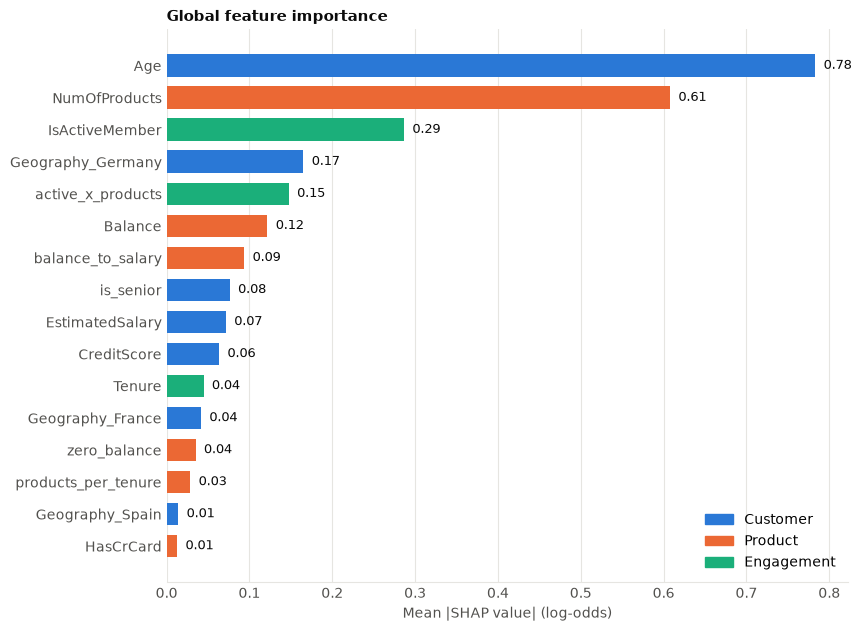

Importance summed by lever (a feature's credit can be split across correlated features, so read this loosely):


,mean_abs_shap_total,share_pct
Customer,1.22,46.849998
Product,0.90,34.689999
Engagement,0.48,18.459999


In [2]:
imp = pd.Series(np.abs(sv).mean(axis=0), index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 6.2), constrained_layout=True)
ax.barh(imp.index, imp.values, color=[LEVER_COLORS[LEVER_OF[f]] for f in imp.index], height=0.7)
for i, v in enumerate(imp.values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", color=INK, fontsize=9)
ax.set_xlabel("Mean |SHAP value| (log-odds)", color=MUTED)
ax.set_title("Global feature importance", loc="left", color=INK, fontsize=11, fontweight="bold")
ax.legend(handles=[Patch(color=c, label=l) for l, c in LEVER_COLORS.items()], frameon=False, loc="lower right")
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(GRID); ax.tick_params(colors=MUTED, length=0)
plt.show()

by_lever = pd.DataFrame({"mean_abs_shap_total": imp.groupby(imp.index.map(LEVER_OF)).sum()})
by_lever["share_pct"] = 100 * by_lever["mean_abs_shap_total"] / by_lever["mean_abs_shap_total"].sum()
print("Importance summed by lever (a feature's credit can be split across correlated features, so read this loosely):")
display(by_lever.sort_values("share_pct", ascending=False).round(2))

## Beeswarm
Each dot is one test customer. Position is the push on churn log-odds; colour is the feature value (red = high, blue = low). Lever shown in brackets.

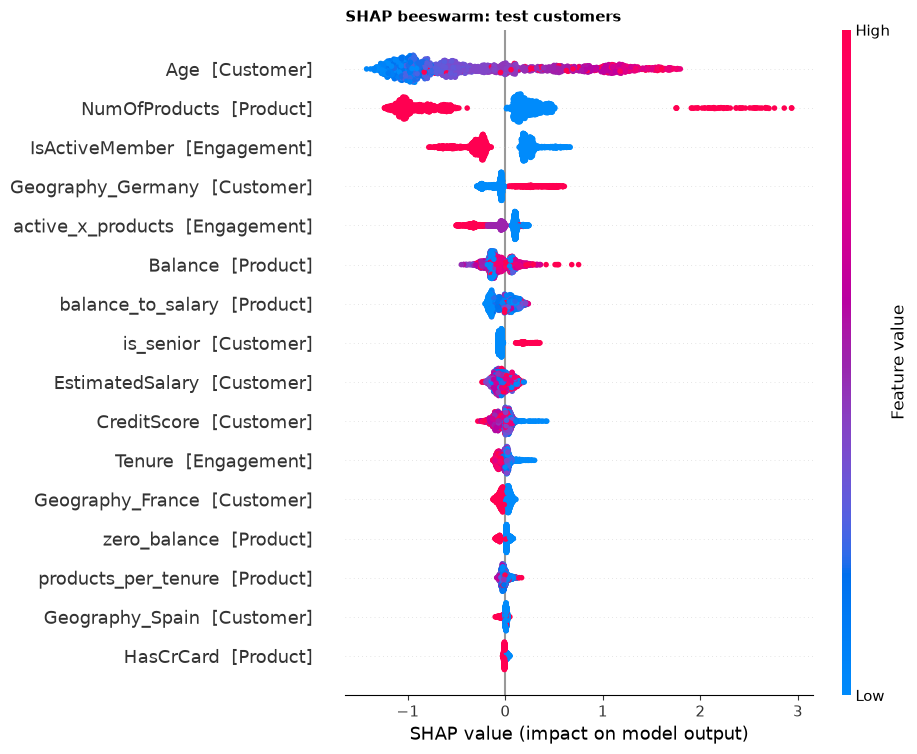

In [3]:
shap.summary_plot(sv, X, feature_names=[f"{c}  [{LEVER_OF[c]}]" for c in X.columns], max_display=18, show=False, plot_size=(9.5, 7.5))
plt.title("SHAP beeswarm: test customers", loc="left", fontsize=11, fontweight="bold")
plt.show()

## Dependence plots
How the push on churn log-odds changes with the feature value. Dot colour shows the feature that interacts most with it.

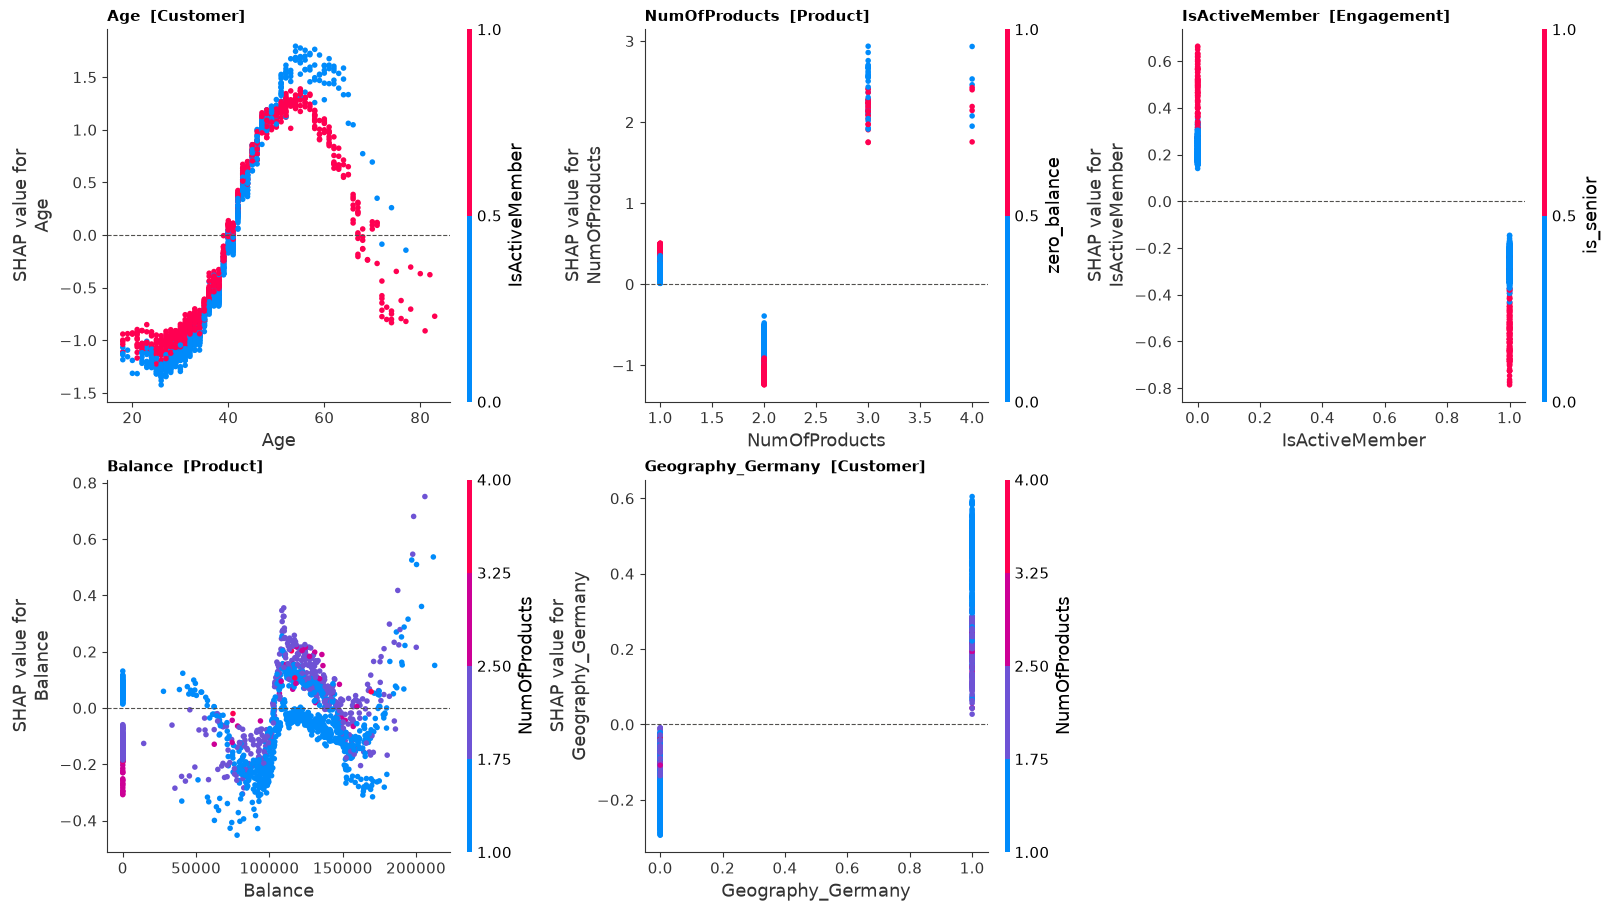

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
for ax, feature in zip(axes.ravel(), ["Age", "NumOfProducts", "IsActiveMember", "Balance", "Geography_Germany"]):
    shap.dependence_plot(feature, sv, X, ax=ax, show=False)
    ax.set_title(f"{feature}  [{LEVER_OF[feature]}]", loc="left", fontsize=11, fontweight="bold")
    ax.axhline(0, color=MUTED, lw=0.8, ls="--")
axes[1, 2].axis("off")
plt.show()

## Three high-risk customers
Chosen to show different routes to a high score: the highest-risk test customer overall, and the highest-risk customers among those holding 2 products and 3-4 products.
Each waterfall starts at the average log-odds and adds each feature's push, ending at that customer's log-odds. Ages and balances are the customer's own values.

,Age,NumOfProducts,IsActiveMember,Balance,Tenure,CreditScore,Geography,risk,churned_actual
Highest risk overall,58,1,0,0.00,4,599,France,1.000,1
"Highest risk, 2 products",61,2,0,129855.72,4,785,Spain,0.847,1
"Highest risk, 3-4 products",52,3,0,116497.31,5,521,Germany,1.000,1


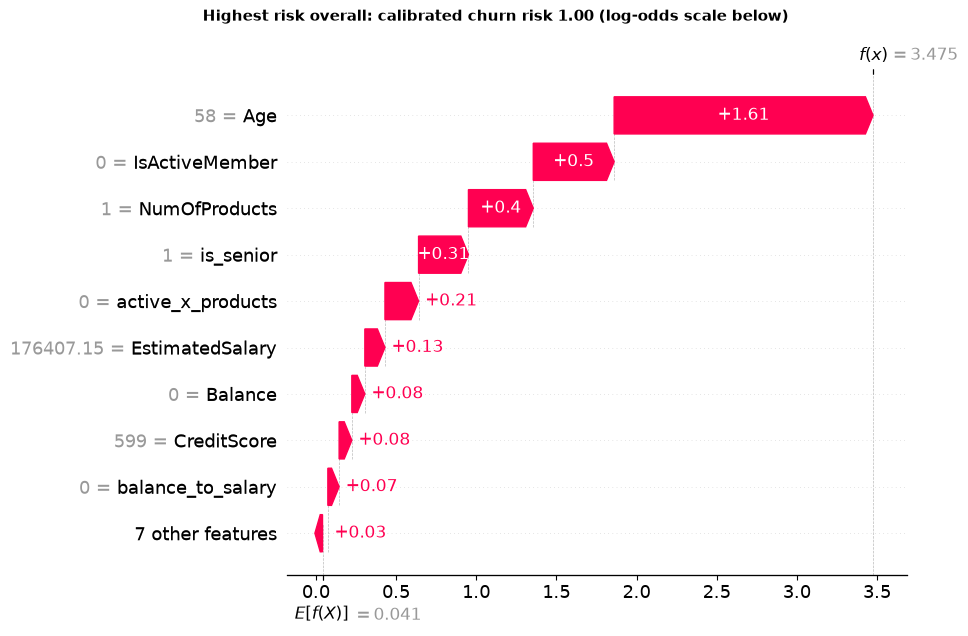

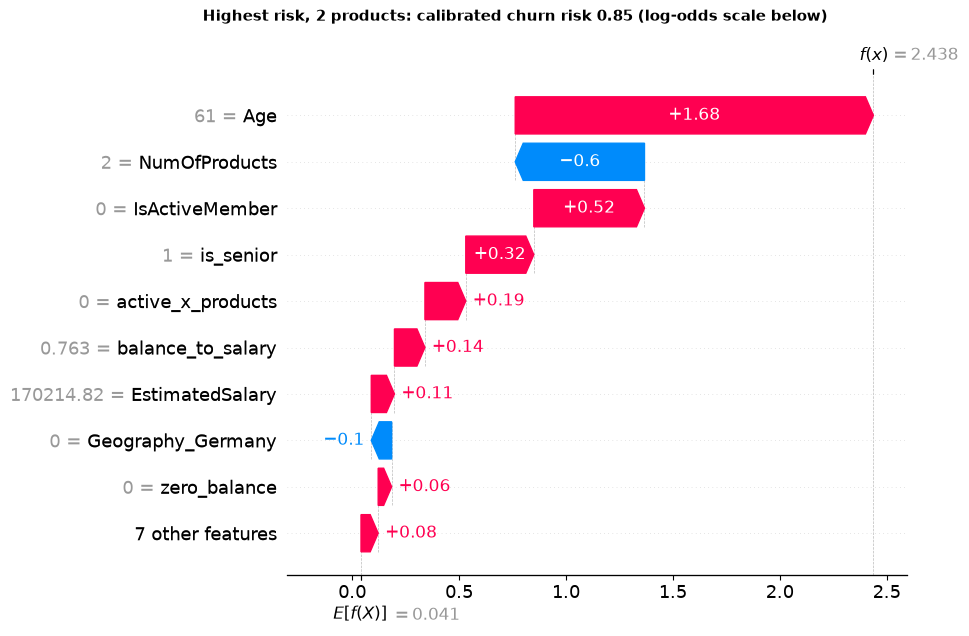

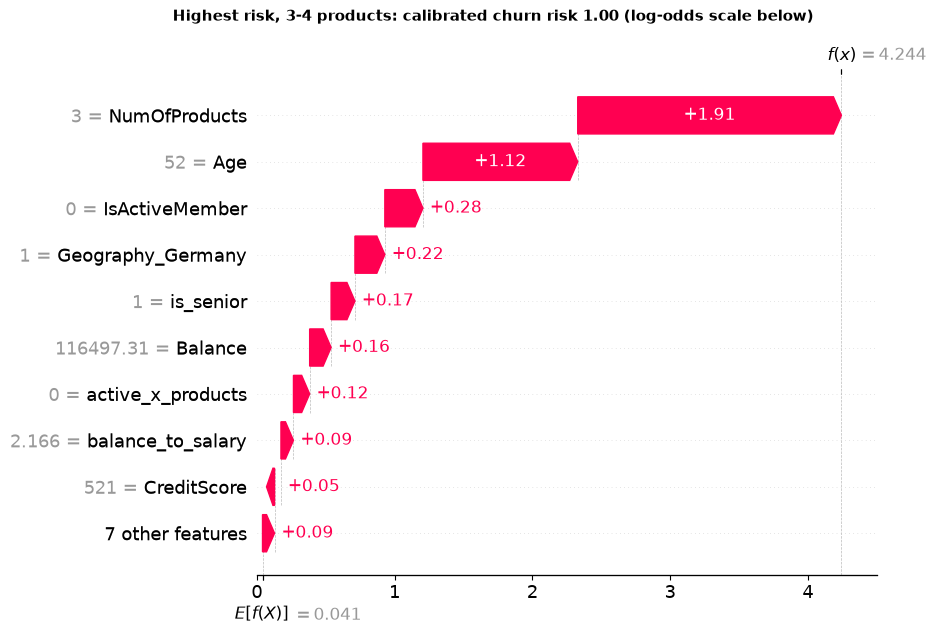

In [5]:
geo = X[["Geography_France", "Geography_Germany", "Geography_Spain"]].idxmax(axis=1).str.replace("Geography_", "")


def top(mask):
    return int(np.argmax(np.where(mask, risk, -1)))


picks = {"Highest risk overall": top(np.ones(len(X), dtype=bool)),
         "Highest risk, 2 products": top((X["NumOfProducts"] == 2).to_numpy()),
         "Highest risk, 3-4 products": top((X["NumOfProducts"] >= 3).to_numpy())}
idx = list(picks.values())
cols = ["Age", "NumOfProducts", "IsActiveMember", "Balance", "Tenure", "CreditScore"]
examples = X.loc[idx, cols].assign(Geography=geo.iloc[idx].values, risk=risk[idx], churned_actual=y[idx])
examples.index = list(picks)
display(examples.round(3))

for label, i in picks.items():
    exp = shap.Explanation(values=sv[i], base_values=base, data=X.iloc[i].to_numpy(), feature_names=list(X.columns))
    shap.plots.waterfall(exp, max_display=10, show=False)
    plt.gcf().suptitle(f"{label}: calibrated churn risk {risk[i]:.2f} (log-odds scale below)", x=0.02, ha="left", fontsize=11, fontweight="bold")
    plt.show()

## Why Gender was dropped from the champion (ablation)
Gender is a sensitive attribute. The Stage 4 champion (registered **v1**) used it. To check how much it added, the same setup was retrained **without** `Gender_Female` and `Gender_Male`:
same train/test split, same XGBoost search space and seed, same calibration choice (`python -m src.models.ablation`).
The table compares that model with v1 on the same test customers, with a 95% confidence interval on the difference from a paired bootstrap (1,000 resamples, both models scored on the same resampled customers).
Because the result showed no measurable loss, the no-Gender model was registered as **v2** and promoted to the `champion` alias (`python -m src.models.promote`); v1 stays in the registry for comparison.
**Everything above this section explains v2, so Gender no longer appears in the SHAP plots.**

In [6]:
import mlflow

mlflow.set_tracking_uri(f"sqlite:///{(root / 'mlflow.db').as_posix()}")
runs = mlflow.search_runs(experiment_names=["bank-churn"])
by_name = runs.set_index("tags.mlflow.runName")
champ_run, abl_run, parent_run = by_name.loc["xgboost_calibrated"], by_name.loc["xgboost_calibrated_no_gender"], by_name.loc["stage5-gender-ablation"]
rows = []
for m, label in (("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC"), ("brier", "Brier (lower is better)")):
    rows.append({"metric": label, "v1 (with Gender)": champ_run[f"metrics.test_{m}"], "v2 (without Gender)": abl_run[f"metrics.test_{m}"],
                 "difference": parent_run[f"metrics.paired_diff_{m}_mean"], "95% CI low": parent_run[f"metrics.paired_diff_{m}_ci_low"],
                 "95% CI high": parent_run[f"metrics.paired_diff_{m}_ci_high"]})
display(pd.DataFrame(rows).set_index("metric").round(4))
print(f"Cross-validation PR-AUC on train: v1 {champ_run['metrics.cv_pr_auc_mean']:.4f}, v2 (without Gender) {abl_run['metrics.cv_pr_auc_mean']:.4f}")

,v1 (with Gender),v2 (without Gender),difference,95% CI low,95% CI high
metric,,,,,
ROC-AUC,0.8646,0.8647,0.0002,-0.0050,0.0059
PR-AUC,0.6949,0.6871,-0.0076,-0.0163,0.0009
Brier (lower is better),0.1034,0.1041,0.0007,-0.0008,0.0021


Cross-validation PR-AUC on train: v1 0.7062, v2 (without Gender) 0.7034


**Result: dropping Gender costs essentially nothing measurable, so the no-Gender model (v2) was promoted to champion.**
- ROC-AUC is unchanged (difference +0.0002, 95% CI -0.0050 to +0.0059) and so is the Brier score (+0.0007, CI -0.0008 to +0.0021).
- PR-AUC is 0.0076 lower without Gender (0.6871 against 0.6949). The 95% interval, -0.0163 to +0.0009, only just includes zero: a small loss of up to about 0.016 is possible, but it cannot be told apart from noise on this test set.
- Cross-validation on the training data agrees: PR-AUC 0.7034 without Gender against 0.7062 with it, well inside one fold standard deviation (about 0.016).

**What it means.** The model ranks churn risk about as well without Gender, so the champion no longer relies on a sensitive attribute. The cost is at most a small PR-AUC loss that the data cannot distinguish from zero.
The retention analysis (notebook 05) was rerun against v2.

**Caveats.** The ablation's search settled on somewhat different tuned settings from v1, so part of any difference is search noise rather than the missing feature, and this is one retraining on one split.
Removing the column does not by itself make the model blind to gender, which is what the proxy check below tests.

## Proxy check: can the other features predict Gender?
Dropping the Gender column does not by itself stop a model from using gender: other features could act as proxies. A direct test is to try to *predict Gender from the 16 features the model uses*,
with 5-fold cross-validated ROC-AUC on the train split. An AUC near 0.5 means the features carry little information about gender (weak proxies); well above 0.5 means they do.
A logistic regression and a gradient-boosted model are tried, and a run with shuffled gender labels shows what "no information" looks like for the same method.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from src.models.registry import load_split

X_tr, _, audit_tr = load_split("train", audit=True)
is_female = audit_tr["Gender_Female"].to_numpy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
boost = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, n_jobs=-1, random_state=42)

rows = []
for name, model, target in (("Logistic regression", logreg, is_female), ("Gradient boosting (XGBoost)", boost, is_female),
                            ("Gradient boosting, shuffled labels (no-information baseline)", boost, np.random.default_rng(42).permutation(is_female))):
    s = cross_val_score(model, X_tr, target, cv=cv, scoring="roc_auc")
    rows.append({"model": name, "CV ROC-AUC (mean)": s.mean(), "sd across folds": s.std()})
display(pd.DataFrame(rows).set_index("model").round(3))
print(f"{len(X_tr):,} train customers, {X_tr.shape[1]} predictors, {is_female.mean():.1%} female")

,CV ROC-AUC (mean),sd across folds
model,,
Logistic regression,0.516,0.010
Gradient boosting (XGBoost),0.509,0.016
"Gradient boosting, shuffled labels (no-information baseline)",0.506,0.009


8,000 train customers, 16 predictors, 45.5% female


**Result: the other features are weak proxies for gender.** Cross-validated ROC-AUC for predicting gender from the 16 model features is **0.516** (sd 0.010) with logistic regression and **0.509** (sd 0.016) with gradient boosting.
The same method given shuffled labels scores 0.506 (sd 0.009), so these results are at chance level: gradient boosting, which would pick up interactions, finds nothing, and logistic regression is only about one fold standard deviation above chance.

**What this shows.** Gender cannot be recovered from the remaining features, so dropping the column does remove gender information from the model in practice, which supports promoting v2.

**What it does not show.** A model can still produce different outcomes for men and women through legitimate features, and this test says nothing about that. For that reason the audit-only `Gender` column is carried into `reports/scored_test_customers.csv` (the model never sees it) so the dashboard can compare how often men and women are selected and their risk scores.
This is one cross-validated check on 8,000 training customers.

## Driver summary in plain English (champion v2: no Gender)

**What the model leans on, in order.** Age (mean |SHAP| 0.78), number of products (0.61), active membership (0.29), Germany (0.17), the active-times-products interaction (0.15) and balance (0.12).
By lever, about 47% of the importance sits with customer attributes, 35% with product features and 18% with engagement (read these shares loosely: correlated features split the credit).

### Actionable levers: things the bank can influence
- **Number of products (Product).** The strongest lever. Holding 2 products lowers risk (push of -1.2 to -0.4 log-odds, typically about -1.0), 1 product raises it slightly (about +0.2), and 3 or 4 products raise it sharply (+1.8 to +2.9).
  The 3-4 product group is small (326 customers in the full data, 66 in the test set), but the pattern matches the EDA. This is an association: it says where churn concentrates, not that moving a customer from 1 to 2 products would keep them. That needs a test.
- **Active membership (Engagement).** Inactive members are pushed toward churn (about +0.2, up to +0.7) and active members away from it (about -0.3, down to -0.8), a swing of roughly 0.5 log-odds at the typical customer, with a further push from the `active_x_products` interaction.
  Activity also changes how much age matters: for customers aged 53-57 the age effect is about +1.3 for active members against about +1.7 for inactive ones. Re-engaging inactive customers is the most practical lever here.

### Targeting variables: who to look at, not something to change
- **Age (Customer).** The biggest single driver and non-linear: customers under about 35 are pushed strongly away from churning (about -1.0), the push rises sharply from the late 30s, stays high across ages 45-65 (typically +1.1 to +1.3), and is mixed above 65.
  Age tells you which customers to prioritise; it cannot be acted on.
- **Geography (Customer).** Being in Germany pushes risk up (about +0.3, up to +0.6); France and Spain are close to neutral. Use it to decide where to investigate (pricing, competition, service), not as a lever.
- **Credit score and salary** matter little (0.06 to 0.07).
- **Balance and tenure.** Weak and uneven. Balance sits slightly below zero for small balances and near zero for 100-150 thousand units; the few customers above about 180 thousand (31 in the test set) show a higher median push, which is too few to trust.
- **Gender is not a model input.** The ablation and proxy check below explain why it was removed and why dropping the column is meaningful. Age remains a sensitive attribute: whether it may be used to decide who receives an offer is a compliance question.

### The three example customers
- *Highest risk overall* (France, age 58, 1 product, zero balance, inactive; risk 1.00): age adds +1.61, inactivity +0.50, holding one product +0.40 and being 50 or over (`is_senior`) +0.31.
- *Highest risk with 2 products* (Spain, age 61, inactive; risk 0.85): holding 2 products is protective (-0.60), but age (+1.68), inactivity (+0.52) and `is_senior` (+0.32) outweigh it.
- *Highest risk with 3-4 products* (Germany, age 52, 3 products, inactive; risk 1.00): the number of products is the largest single push (+1.91), then age (+1.12), inactivity (+0.28) and Germany (+0.22).
All three actually churned, which fits the model, but three hand-picked customers are illustrations, not evidence.

### Caveats
SHAP shows what the model relies on, not what causes churn. Correlated features (age and `is_senior`, products and `active_x_products`) share credit, so individual numbers are approximate.
Everything here is from 2,000 test customers and one fitted model; the shapes (age rise, products pattern, activity gap) match the Stage 2 EDA, which is reassuring, but the exact values should not be over-read.